# 23B — Environmental Anomaly Decomposition
## Separating fire-history novelty from environmental surprise

### Why this notebook exists

Notebook 23 found that **Emerging-3** events are strongly anomalous relative to recent fire history, but only modestly different from Persistent events under the weather-only model.

That result is useful, but it has two methodological issues:

1. **Circularity**  
   Emerging-3 is defined by absence of recent local fire, so a fire-history model will naturally call many Emerging events surprising.

2. **Seasonal / temporal distribution shift**  
   August has far more positive hotspot activity than May–July. A global monthly anomaly rank can therefore mix:
   - true spatial/environmental surprise, and
   - simple seasonal change.

### Goal

This notebook decomposes each **actual August hotspot event** into two independent axes:

- **History anomaly**  
  How unexpected is the hotspot given local current/recent fire activity?

- **Environmental anomaly**  
  How unexpected is the hotspot given same-day ERA5 weather, **relative to the other T2 cells on that same day**?

The main candidate of interest is:

> **high history anomaly + high environmental anomaly**

This is still only an **unusual hotspot candidate**.

It is **not** a label of:
- anthropogenic ignition,
- intentional burning,
- illegal burning,
- plantation clearing,
- or natural ignition.

External evidence such as lightning, land cover, roads/accessibility, peatland, and land-use change is required before discussing possible ignition context.

### Data discipline

- Model fitting: **2026-05-08 → 2026-07-31**
- Development analysis: **August 2026**
- September: **not used**

In [3]:
# 1. Imports

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 260)

RANDOM_STATE = 42

In [4]:
# 2. Resolve project root

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    candidate = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )
    if candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/processed/regional_025/"
        "karhut_ml_dataset_regional_025.csv. "
        "Open this notebook from the skripsi-karhut project or set PROJECT_ROOT manually."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "environmental_anomaly_decomposition"
    / "t2"
)

FIGURES_DIR = RESULTS_DIR / "figures"
EXPORT_DIR = RESULTS_DIR / "exports"

for p in [RESULTS_DIR, FIGURES_DIR, EXPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_PATH   :", DATA_PATH)
print("RESULTS_DIR :", RESULTS_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
DATA_PATH   : c:\Users\Asus\Documents\skripsi-karhut\data\processed\regional_025\karhut_ml_dataset_regional_025.csv
RESULTS_DIR : c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_anomaly_decomposition\t2


In [5]:
# 3. Load regional dataset

regional = pd.read_csv(DATA_PATH, parse_dates=["date"])

print("Rows :", len(regional))
print("Dates:", regional["date"].min().date(), "→", regional["date"].max().date())
print("Nodes:", regional["cell_id"].nunique())

display(regional.head())

Rows : 16625
Dates: 2026-05-08 → 2026-09-09
Nodes: 133


,date,cell_id,fire_count,frp_sum,fire_active,node_index,grid_lat,grid_lon,land_fraction,jrc_mean_water_occurrence,jrc_water_any_fraction,jrc_water50_fraction,jrc_water90_fraction,fire_count_lag1,fire_count_lag3,fire_count_lag7,frp_sum_lag1,frp_sum_lag3,frp_sum_lag7,fire_count_roll3,frp_sum_roll3,fire_count_roll7,frp_sum_roll7,target_fire_active_t1,active_days_prev3_incl_t,event_type_3d,active_days_prev7_incl_t,event_type_7d,temperature_mean,temperature_max,relative_humidity_mean,precipitation_sum,boundary_layer_height_mean,vapour_pressure_deficit_mean,wind_speed_mean,wind_speed_max,wind_u_mean,wind_v_mean
0,2026-05-08,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,26.275000,30.5,91.458333,15.4,238.750000,0.317917,3.929167,5.6,0.691170,-1.995124
1,2026-05-09,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,27.291667,31.2,90.250000,8.2,214.166667,0.386250,3.108333,5.1,0.868119,1.602951
2,2026-05-10,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,26.941667,31.6,89.875000,2.2,175.625000,0.405833,4.250000,7.0,-2.669541,1.563219
3,2026-05-11,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,28.187500,34.2,83.541667,2.3,420.208333,0.734167,3.991667,6.6,-0.189994,1.040999
4,2026-05-12,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,Negative,0.0,Negative,27.291667,31.4,88.416667,6.2,271.041667,0.471250,3.854167,5.4,1.313670,1.731916


In [6]:
# 4. Locked feature definitions

FIRE_HISTORY_FEATURES = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

CURRENT_DAY_FIRE_FEATURES = [
    "fire_active",
    "fire_count",
    "frp_sum",
]

WEATHER_FEATURES = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

FIRE13 = CURRENT_DAY_FIRE_FEATURES + FIRE_HISTORY_FEATURES
ENV10 = WEATHER_FEATURES

TARGET = "target_fire_active_t1"

STATIC_AUDIT_FEATURES = [
    c for c in [
        "land_fraction",
        "jrc_mean_water_occurrence",
        "jrc_water_any_fraction",
        "jrc_water50_fraction",
        "jrc_water90_fraction",
    ]
    if c in regional.columns
]

required = {
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "active_days_prev3_incl_t",
    "event_type_3d",
    TARGET,
    *FIRE13,
    *ENV10,
}

missing = sorted(required - set(regional.columns))
if missing:
    raise ValueError("Missing required columns:\n" + "\n".join(missing))

print("FIRE13:", len(FIRE13))
print("ENV10  :", len(ENV10))
print("Static audit features:", STATIC_AUDIT_FEATURES)

FIRE13: 13
ENV10  : 10
Static audit features: ['land_fraction', 'jrc_mean_water_occurrence', 'jrc_water_any_fraction', 'jrc_water50_fraction', 'jrc_water90_fraction']


In [7]:
# 5. Train / August development split
# September remains excluded.

TRAIN_START = pd.Timestamp("2026-05-08")
TRAIN_END = pd.Timestamp("2026-07-31")
VAL_START = pd.Timestamp("2026-08-01")
VAL_END = pd.Timestamp("2026-08-31")

model_data = regional[
    regional[FIRE13 + ENV10 + [TARGET]].notna().all(axis=1)
].copy()

train = model_data[
    model_data["date"].between(TRAIN_START, TRAIN_END)
].copy()

aug = model_data[
    model_data["date"].between(VAL_START, VAL_END)
].copy()

sep = model_data[
    model_data["date"] > VAL_END
].copy()

print("Train :", len(train), "| positives:", int(train[TARGET].sum()), "| rate:", round(train[TARGET].mean(), 6))
print("August:", len(aug), "| positives:", int(aug[TARGET].sum()), "| rate:", round(aug[TARGET].mean(), 6))
print("September rows excluded:", len(sep))

assert train["date"].max() < aug["date"].min()
assert train.duplicated(["date", "cell_id"]).sum() == 0
assert aug.duplicated(["date", "cell_id"]).sum() == 0

Train : 11305 | positives: 833 | rate: 0.073684
August: 4123 | positives: 2169 | rate: 0.526073
September rows excluded: 1197


# PART A — Two independent expectedness models

We deliberately **do not average FIRE13 and ENV10 into one anomaly score**.

### FIRE13
Measures local fire-history/context expectedness.

### ENV10
Measures weather-based expectedness.

To check whether environmental anomaly is merely an artifact of a linear Logistic Regression model, we also fit a **nonlinear HistGradientBoosting sensitivity model** using exactly the same ENV10 inputs.

Important:
- Logistic Regression remains the **primary interpretable environmental model**.
- HistGradientBoosting is a **robustness check**, not a new final thesis model.
- No September labels are used.

In [8]:
# 6. Model helpers

def balanced_sample_weights(y):
    y = np.asarray(y).astype(int)
    n = len(y)
    n_pos = max(int((y == 1).sum()), 1)
    n_neg = max(int((y == 0).sum()), 1)

    w_pos = n / (2.0 * n_pos)
    w_neg = n / (2.0 * n_neg)

    return np.where(y == 1, w_pos, w_neg)


def make_lr():
    return Pipeline([
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2500,
                random_state=RANDOM_STATE,
            ),
        ),
    ])


fire_lr = make_lr()
env_lr = make_lr()

fire_lr.fit(train[FIRE13], train[TARGET])
env_lr.fit(train[ENV10], train[TARGET])

env_hgb = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=150,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=1.0,
    random_state=RANDOM_STATE,
)

env_hgb.fit(
    train[ENV10],
    train[TARGET],
    sample_weight=balanced_sample_weights(train[TARGET]),
)

print("FIRE13 LR fitted.")
print("ENV10 LR fitted.")
print("ENV10 HGB sensitivity model fitted.")

FIRE13 LR fitted.
ENV10 LR fitted.
ENV10 HGB sensitivity model fitted.


In [9]:
# 7. Score August

aug_scored = aug.copy()

aug_scored["fire_expected_lr"] = fire_lr.predict_proba(
    aug_scored[FIRE13]
)[:, 1]

aug_scored["env_expected_lr"] = env_lr.predict_proba(
    aug_scored[ENV10]
)[:, 1]

aug_scored["env_expected_hgb"] = env_hgb.predict_proba(
    aug_scored[ENV10]
)[:, 1]

display(
    aug_scored[
        [
            "date",
            "cell_id",
            TARGET,
            "event_type_3d",
            "fire_expected_lr",
            "env_expected_lr",
            "env_expected_hgb",
        ]
    ].head()
)

,date,cell_id,target_fire_active_t1,event_type_3d,fire_expected_lr,env_expected_lr,env_expected_hgb
85,2026-08-01,regional025_10_22,0,Negative,0.294872,0.524814,0.513333
86,2026-08-02,regional025_10_22,0,Negative,0.294872,0.668676,0.629405
87,2026-08-03,regional025_10_22,0,Negative,0.294872,0.661600,0.590112
88,2026-08-04,regional025_10_22,1,Emerging,0.294872,0.578717,0.609232
89,2026-08-05,regional025_10_22,1,Persistent,0.789134,0.693405,0.798204


In [10]:
# 8. Performance audit
# This tells us whether the environmental models contain usable predictive signal.

def metric_bundle(df, score_col):
    y = df[TARGET].to_numpy()
    s = df[score_col].to_numpy()

    result = {
        "Rows": len(df),
        "Positives": int(y.sum()),
        "Prevalence": float(y.mean()),
        "PR-AUC": float(average_precision_score(y, s)),
    }

    result["ROC-AUC"] = (
        float(roc_auc_score(y, s))
        if len(np.unique(y)) == 2
        else np.nan
    )

    return result


rows = []

for model_name, score_col in [
    ("FIRE13-LR", "fire_expected_lr"),
    ("ENV10-LR", "env_expected_lr"),
    ("ENV10-HGB sensitivity", "env_expected_hgb"),
]:
    rows.append({
        "Model": model_name,
        "Context": "Overall",
        **metric_bundle(aug_scored, score_col),
    })

    emerging_eligible = aug_scored["active_days_prev3_incl_t"].eq(0)
    persistent_context = ~emerging_eligible

    rows.append({
        "Model": model_name,
        "Context": "Emerging-3 eligible",
        **metric_bundle(aug_scored.loc[emerging_eligible], score_col),
    })

    rows.append({
        "Model": model_name,
        "Context": "Persistent-context",
        **metric_bundle(aug_scored.loc[persistent_context], score_col),
    })

model_metrics = pd.DataFrame(rows)
display(model_metrics)

,Model,Context,Rows,Positives,Prevalence,PR-AUC,ROC-AUC
0,FIRE13-LR,Overall,4123,2169,0.526073,0.877455,0.858476
1,FIRE13-LR,Emerging-3 eligible,1241,224,0.180500,0.277072,0.649198
2,FIRE13-LR,Persistent-context,2882,1945,0.674879,0.909001,0.828667
3,ENV10-LR,Overall,4123,2169,0.526073,0.594208,0.581621
4,ENV10-LR,Emerging-3 eligible,1241,224,0.180500,0.180150,0.496106
5,ENV10-LR,Persistent-context,2882,1945,0.674879,0.732253,0.580831
6,ENV10-HGB sensitivity,Overall,4123,2169,0.526073,0.569584,0.536859
7,ENV10-HGB sensitivity,Emerging-3 eligible,1241,224,0.180500,0.176119,0.479560
8,ENV10-HGB sensitivity,Persistent-context,2882,1945,0.674879,0.716502,0.551283


# PART B — Same-day anomaly ranks

This is the main correction from Notebook 23.

Instead of ranking an August event against the whole month, each score is ranked **within the same predictor date** across all T2 cells.

For a given day:

- a cell with high expectedness gets a **low anomaly rank**;
- a cell with low expectedness gets a **high anomaly rank**.

This removes much of the month-level seasonal shift because the question becomes:

> **“On this specific day, was this cell unusually low-risk relative to the other cells, yet a hotspot appeared on the next day?”**

In [11]:
# 9. Create same-day anomaly ranks across all cells

def within_day_low_score_rank(df, score_col):
    return (
        df.groupby("date")[score_col]
        .transform(
            lambda s: s.rank(
                pct=True,
                ascending=False,
                method="average",
            )
        )
    )


aug_scored["history_anomaly_day_rank"] = within_day_low_score_rank(
    aug_scored,
    "fire_expected_lr",
)

aug_scored["env_anomaly_day_rank_lr"] = within_day_low_score_rank(
    aug_scored,
    "env_expected_lr",
)

aug_scored["env_anomaly_day_rank_hgb"] = within_day_low_score_rank(
    aug_scored,
    "env_expected_hgb",
)

# Positive events only: these are actual FIRMS detections at t+1.
pos = aug_scored[aug_scored[TARGET].eq(1)].copy()

pos["event_date"] = pos["date"] + pd.Timedelta(days=1)
pos["is_emerging3"] = pos["active_days_prev3_incl_t"].eq(0)
pos["research_group"] = np.where(
    pos["is_emerging3"],
    "Emerging-3",
    "Persistent",
)

print("August positive events:", len(pos))
print("Emerging-3:", int(pos["is_emerging3"].sum()))
print("Persistent:", int((~pos["is_emerging3"]).sum()))

August positive events: 2169
Emerging-3: 224
Persistent: 1945


In [12]:
# 10. Summary: Emerging vs Persistent using same-day ranks

same_day_summary = (
    pos
    .groupby("research_group")
    .agg(
        events=("cell_id", "size"),
        history_mean=("history_anomaly_day_rank", "mean"),
        history_median=("history_anomaly_day_rank", "median"),
        env_lr_mean=("env_anomaly_day_rank_lr", "mean"),
        env_lr_median=("env_anomaly_day_rank_lr", "median"),
        env_hgb_mean=("env_anomaly_day_rank_hgb", "mean"),
        env_hgb_median=("env_anomaly_day_rank_hgb", "median"),
    )
    .reset_index()
)

display(same_day_summary)

,research_group,events,history_mean,history_median,env_lr_mean,env_lr_median,env_hgb_mean,env_hgb_median
0,Emerging-3,224,0.755119,0.796992,0.544945,0.567669,0.535731,0.552632
1,Persistent,1945,0.310248,0.278195,0.481539,0.496241,0.487210,0.484962


In [13]:
# 11. Date-block bootstrap of Emerging - Persistent median difference
# We bootstrap dates, not individual rows, to reduce false confidence from repeated events.

def date_block_bootstrap_median_diff(
    df,
    value_col,
    n_boot=2000,
    seed=42,
):
    rng = np.random.default_rng(seed)
    dates = np.array(sorted(df["event_date"].dropna().unique()))

    observed_em = df.loc[
        df["research_group"].eq("Emerging-3"),
        value_col,
    ].median()

    observed_pe = df.loc[
        df["research_group"].eq("Persistent"),
        value_col,
    ].median()

    observed = float(observed_em - observed_pe)

    boot = []

    for _ in range(n_boot):
        sampled_dates = rng.choice(
            dates,
            size=len(dates),
            replace=True,
        )

        pieces = [
            df[df["event_date"].eq(d)]
            for d in sampled_dates
        ]

        b = pd.concat(pieces, ignore_index=True)

        em = b.loc[
            b["research_group"].eq("Emerging-3"),
            value_col,
        ]

        pe = b.loc[
            b["research_group"].eq("Persistent"),
            value_col,
        ]

        if len(em) == 0 or len(pe) == 0:
            continue

        boot.append(float(em.median() - pe.median()))

    lo, hi = np.quantile(boot, [0.025, 0.975])

    return {
        "Metric": value_col,
        "Observed median difference": observed,
        "Bootstrap 2.5%": float(lo),
        "Bootstrap 97.5%": float(hi),
        "Bootstrap samples": len(boot),
    }


bootstrap_results = pd.DataFrame([
    date_block_bootstrap_median_diff(
        pos,
        "history_anomaly_day_rank",
    ),
    date_block_bootstrap_median_diff(
        pos,
        "env_anomaly_day_rank_lr",
    ),
    date_block_bootstrap_median_diff(
        pos,
        "env_anomaly_day_rank_hgb",
    ),
])

display(bootstrap_results)

,Metric,Observed median difference,Bootstrap 2.5%,Bootstrap 97.5%,Bootstrap samples
0,history_anomaly_day_rank,0.518797,0.477444,0.563910,2000
1,env_anomaly_day_rank_lr,0.071429,0.014944,0.150376,2000
2,env_anomaly_day_rank_hgb,0.067669,0.007519,0.127820,2000


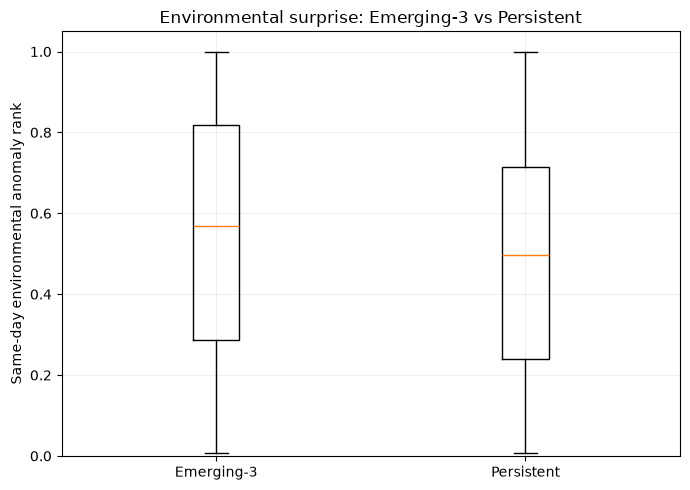

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_anomaly_decomposition\t2\figures\01_same_day_environmental_anomaly.png


In [14]:
# 12. Plot same-day environmental anomaly distributions

groups = [
    pos.loc[
        pos["research_group"].eq(g),
        "env_anomaly_day_rank_lr",
    ].dropna().to_numpy()
    for g in ["Emerging-3", "Persistent"]
]

fig, ax = plt.subplots(figsize=(7, 5))

ax.boxplot(
    groups,
    tick_labels=["Emerging-3", "Persistent"],
)

ax.set_ylim(0, 1.05)
ax.set_ylabel("Same-day environmental anomaly rank")
ax.set_title("Environmental surprise: Emerging-3 vs Persistent")
ax.grid(alpha=0.2)

plt.tight_layout()

path = FIGURES_DIR / "01_same_day_environmental_anomaly.png"
plt.savefig(path, dpi=190, bbox_inches="tight")
plt.show()

print("Saved:", path)

# PART C — Two-axis anomaly decomposition

We now stop using the Notebook 23 `consensus_anomaly_rank`.

Primary axes:

### X-axis — History anomaly
`history_anomaly_day_rank`

### Y-axis — Environmental anomaly
`env_anomaly_day_rank_lr`

The environmental HGB score is used only for robustness.

For an exploratory screening threshold we use a **fixed 0.80 rank**.

This threshold is not optimized for August performance.  
It simply means approximately the most unusual 20% of cells on each axis for a given day.

In [15]:
# 13. Fixed exploratory quadrant definition

PRIMARY_THRESHOLD = 0.80

pos["high_history_anomaly"] = (
    pos["history_anomaly_day_rank"] >= PRIMARY_THRESHOLD
)

pos["high_environment_anomaly"] = (
    pos["env_anomaly_day_rank_lr"] >= PRIMARY_THRESHOLD
)

pos["anomaly_quadrant"] = np.select(
    [
        pos["high_history_anomaly"] & pos["high_environment_anomaly"],
        pos["high_history_anomaly"] & ~pos["high_environment_anomaly"],
        ~pos["high_history_anomaly"] & pos["high_environment_anomaly"],
    ],
    [
        "Q1 Joint-high anomaly candidate",
        "Q2 History-novel / environment-plausible",
        "Q3 Environment-unusual / history-supported",
    ],
    default="Q4 Expected-context",
)

quadrant_counts = (
    pd.crosstab(
        pos["research_group"],
        pos["anomaly_quadrant"],
        margins=True,
    )
)

display(quadrant_counts)

anomaly_quadrant,Q1 Joint-high anomaly candidate,Q2 History-novel / environment-plausible,Q3 Environment-unusual / history-supported,Q4 Expected-context,All
research_group,,,,,
Emerging-3,29,82,34,79,224
Persistent,6,14,286,1639,1945
All,35,96,320,1718,2169


In [16]:
# 14. Quadrant percentages within Emerging vs Persistent

quadrant_share = (
    pos
    .groupby(["research_group", "anomaly_quadrant"])
    .size()
    .rename("events")
    .reset_index()
)

quadrant_share["share_within_group"] = (
    quadrant_share["events"]
    / quadrant_share.groupby("research_group")["events"].transform("sum")
)

display(
    quadrant_share.sort_values(
        ["research_group", "share_within_group"],
        ascending=[True, False],
    )
)

,research_group,anomaly_quadrant,events,share_within_group
1,Emerging-3,Q2 History-novel / environment-plausible,82,0.366071
3,Emerging-3,Q4 Expected-context,79,0.352679
2,Emerging-3,Q3 Environment-unusual / history-supported,34,0.151786
0,Emerging-3,Q1 Joint-high anomaly candidate,29,0.129464
7,Persistent,Q4 Expected-context,1639,0.842674
6,Persistent,Q3 Environment-unusual / history-supported,286,0.147044
5,Persistent,Q2 History-novel / environment-plausible,14,0.007198
4,Persistent,Q1 Joint-high anomaly candidate,6,0.003085


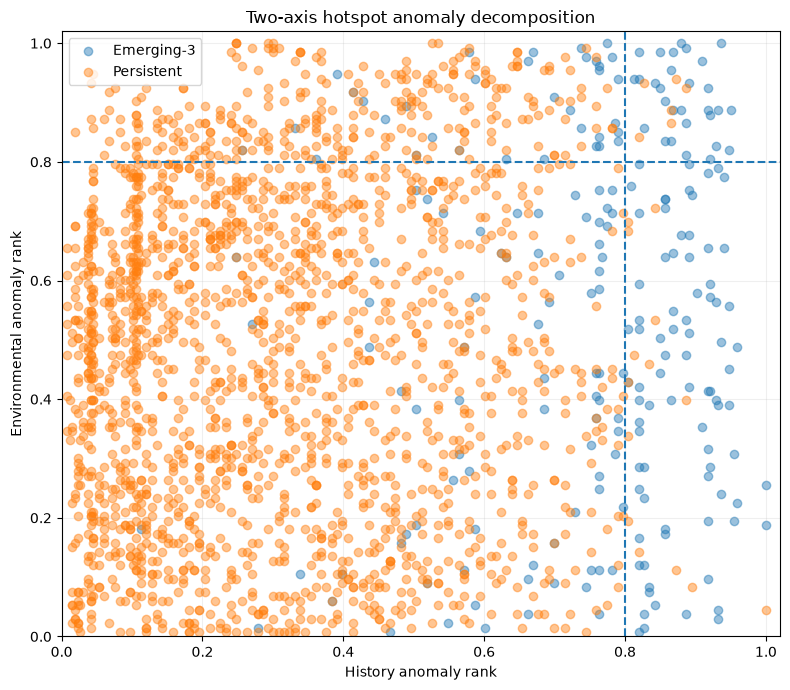

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_anomaly_decomposition\t2\figures\02_history_vs_environment_anomaly.png


In [17]:
# 15. Two-axis scatter

fig, ax = plt.subplots(figsize=(8, 7))

for group, subset in pos.groupby("research_group"):
    ax.scatter(
        subset["history_anomaly_day_rank"],
        subset["env_anomaly_day_rank_lr"],
        alpha=0.45,
        label=group,
    )

ax.axvline(PRIMARY_THRESHOLD, linestyle="--")
ax.axhline(PRIMARY_THRESHOLD, linestyle="--")

ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_xlabel("History anomaly rank")
ax.set_ylabel("Environmental anomaly rank")
ax.set_title("Two-axis hotspot anomaly decomposition")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

path = FIGURES_DIR / "02_history_vs_environment_anomaly.png"
plt.savefig(path, dpi=190, bbox_inches="tight")
plt.show()

print("Saved:", path)

## Quadrant interpretation

### Q1 — Joint-high anomaly candidate
High history anomaly + high environmental anomaly.

This is the most interesting group for later contextual investigation.

Still **not anthropogenic by definition**.

### Q2 — History-novel / environment-plausible
No recent local fire pattern, but same-day weather makes the location relatively plausible for fire.

This is a key reason why:

> Emerging-3 ≠ suspicious hotspot.

### Q3 — Environment-unusual / history-supported
The environment looks unusual, but local fire history already supports continued activity.

### Q4 — Expected-context
Neither axis is especially unusual.

In [18]:
# 16. Candidate table: Q1 joint-high events

joint_candidates = (
    pos[
        pos["anomaly_quadrant"].eq(
            "Q1 Joint-high anomaly candidate"
        )
    ]
    .copy()
)

joint_candidates["joint_rank_score"] = (
    joint_candidates[
        [
            "history_anomaly_day_rank",
            "env_anomaly_day_rank_lr",
        ]
    ].mean(axis=1)
)

joint_candidates = joint_candidates.sort_values(
    [
        "joint_rank_score",
        "env_anomaly_day_rank_lr",
        "history_anomaly_day_rank",
    ],
    ascending=False,
)

candidate_cols = [
    "event_date",
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "research_group",
    "active_days_prev3_incl_t",
    "fire_active",
    "fire_count",
    "frp_sum",
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "history_anomaly_day_rank",
    "env_anomaly_day_rank_lr",
    "env_anomaly_day_rank_hgb",
    "joint_rank_score",
    *STATIC_AUDIT_FEATURES,
]

candidate_cols = list(dict.fromkeys(candidate_cols))

print("Q1 joint-high events:", len(joint_candidates))
print("Emerging-3 among Q1:", int(joint_candidates["is_emerging3"].sum()))
print("Persistent among Q1:", int((~joint_candidates["is_emerging3"]).sum()))

display(joint_candidates[candidate_cols].head(30))

Q1 joint-high events: 35
Emerging-3 among Q1: 29
Persistent among Q1: 6


,event_date,date,cell_id,grid_lat,grid_lon,research_group,active_days_prev3_incl_t,fire_active,fire_count,frp_sum,temperature_mean,temperature_max,relative_humidity_mean,precipitation_sum,vapour_pressure_deficit_mean,wind_speed_mean,history_anomaly_day_rank,env_anomaly_day_rank_lr,env_anomaly_day_rank_hgb,joint_rank_score,land_fraction,jrc_mean_water_occurrence,jrc_water_any_fraction,jrc_water50_fraction,jrc_water90_fraction
15108,2026-08-25,2026-08-24,regional025_8_34,-2.375,116.625,Emerging-3,0.0,0,0.0,0.0,27.400000,27.8,75.916667,0.0,0.880417,25.779167,0.936090,1.000000,0.909774,0.968045,0.281019,73.065750,0.748730,0.744526,0.739155
15115,2026-09-01,2026-08-31,regional025_8_34,-2.375,116.625,Emerging-3,0.0,0,0.0,0.0,27.633333,28.0,78.208333,0.0,0.802500,25.516667,0.879699,1.000000,0.984962,0.939850,0.281019,73.065750,0.748730,0.744526,0.739155
4592,2026-08-09,2026-08-08,regional025_12_34,-1.375,116.625,Emerging-3,0.0,0,0.0,0.0,27.825000,30.4,76.875000,0.0,0.891250,13.087500,0.887218,0.992481,0.947368,0.939850,0.699753,31.031973,0.327184,0.313676,0.305423
13487,2026-08-29,2026-08-28,regional025_7_33,-2.625,116.375,Emerging-3,0.0,0,0.0,0.0,26.925000,29.3,73.208333,0.0,0.978750,16.954167,0.909774,0.969925,0.669173,0.939850,0.463438,50.938248,0.542637,0.514815,0.500421
16591,2026-08-08,2026-08-07,regional025_9_33,-2.125,116.375,Emerging-3,0.0,0,0.0,0.0,27.645833,29.9,74.708333,0.0,0.958750,16.737500,0.868421,0.984962,0.834586,0.926692,0.680458,21.283581,0.285021,0.207172,0.189650
11972,2026-08-14,2026-08-13,regional025_6_33,-2.875,116.375,Emerging-3,0.0,0,0.0,0.0,27.875000,28.1,77.541667,0.0,0.843333,19.962500,0.917293,0.924812,0.977444,0.921053,0.380947,62.648907,0.643862,0.635383,0.629557
5228,2026-08-20,2026-08-19,regional025_13_26,-1.125,114.625,Emerging-3,0.0,0,0.0,0.0,27.783333,32.8,62.708333,0.0,1.499167,5.116667,0.951128,0.887218,0.593985,0.919173,1.000000,0.016362,0.002228,0.000000,0.000000
11976,2026-08-18,2026-08-17,regional025_6_33,-2.875,116.375,Emerging-3,0.0,0,0.0,0.0,27.516667,28.1,77.208333,0.0,0.840000,19.370833,0.849624,0.984962,0.984962,0.917293,0.380947,62.648907,0.643862,0.635383,0.629557
5343,2026-08-10,2026-08-09,regional025_13_27,-1.125,114.875,Emerging-3,0.0,0,0.0,0.0,26.958333,33.2,73.458333,0.0,1.081250,4.854167,0.890977,0.932331,0.721805,0.911654,1.000000,1.502703,0.021883,0.016283,0.009480
14976,2026-08-18,2026-08-17,regional025_8_33,-2.375,116.375,Emerging-3,0.0,0,0.0,0.0,27.704167,31.3,76.833333,0.0,0.914167,14.995833,0.864662,0.954887,0.812030,0.909774,0.998340,1.069439,0.023713,0.009830,0.003295


In [19]:
# 17. Environmental-model robustness
# Do LR and HGB flag similar events as environmentally unusual?

pos["high_env_lr"] = (
    pos["env_anomaly_day_rank_lr"] >= PRIMARY_THRESHOLD
)

pos["high_env_hgb"] = (
    pos["env_anomaly_day_rank_hgb"] >= PRIMARY_THRESHOLD
)

a = set(
    pos.index[pos["high_env_lr"]]
)

b = set(
    pos.index[pos["high_env_hgb"]]
)

intersection = len(a & b)
union = len(a | b)
jaccard = intersection / union if union else np.nan

rank_corr = (
    pos["env_anomaly_day_rank_lr"]
    .rank(method="average")
    .corr(
        pos["env_anomaly_day_rank_hgb"]
        .rank(method="average")
    )
)

robustness = pd.DataFrame({
    "Metric": [
        "Rank correlation LR vs HGB",
        "Top-20% environmental anomaly Jaccard",
        "LR high-env events",
        "HGB high-env events",
        "Intersection",
    ],
    "Value": [
        rank_corr,
        jaccard,
        int(pos["high_env_lr"].sum()),
        int(pos["high_env_hgb"].sum()),
        intersection,
    ],
})

display(robustness)

,Metric,Value
0,Rank correlation LR vs HGB,0.504503
1,Top-20% environmental anomaly Jaccard,0.231379
2,LR high-env events,355.000000
3,HGB high-env events,422.000000
4,Intersection,146.000000


### How to interpret robustness

If LR and HGB environmental anomaly ranks agree strongly:
- the environmental anomaly signal is less likely to be a pure linear-model artifact.

If agreement is weak:
- do **not** freeze the environmental anomaly definition yet;
- the next step should refine the environmental expectedness model before moving to GeoMAE.

In [20]:
# 18. Threshold sensitivity
# We do not optimize thresholds; we inspect 0.75 / 0.80 / 0.90.

threshold_rows = []

for q in [0.75, 0.80, 0.90]:
    high_hist = pos["history_anomaly_day_rank"] >= q
    high_env = pos["env_anomaly_day_rank_lr"] >= q
    joint = high_hist & high_env

    for group in ["Emerging-3", "Persistent", "All"]:
        if group == "All":
            mask = pd.Series(True, index=pos.index)
        else:
            mask = pos["research_group"].eq(group)

        n = int(mask.sum())
        joint_n = int((mask & joint).sum())

        threshold_rows.append({
            "Threshold": q,
            "Group": group,
            "Events": n,
            "Joint-high events": joint_n,
            "Joint-high share": joint_n / n if n else np.nan,
        })

threshold_sensitivity = pd.DataFrame(threshold_rows)
display(threshold_sensitivity)

,Threshold,Group,Events,Joint-high events,Joint-high share
0,0.75,Emerging-3,224,50,0.223214
1,0.75,Persistent,1945,13,0.006684
2,0.75,All,2169,63,0.029046
3,0.80,Emerging-3,224,29,0.129464
4,0.80,Persistent,1945,6,0.003085
5,0.80,All,2169,35,0.016136
6,0.90,Emerging-3,224,3,0.013393
7,0.90,Persistent,1945,0,0.000000
8,0.90,All,2169,3,0.001383


,date,positive_rate,positives,mean_env_expected_lr,mean_env_expected_hgb,mean_fire_expected_lr
0,2026-08-01,0.263158,35,0.606083,0.571042,0.512624
1,2026-08-02,0.000000,0,0.669776,0.605643,0.514933
2,2026-08-03,0.172932,23,0.691614,0.604640,0.449172
3,2026-08-04,0.458647,61,0.608215,0.572870,0.463599
4,2026-08-05,0.458647,61,0.672202,0.632234,0.587618


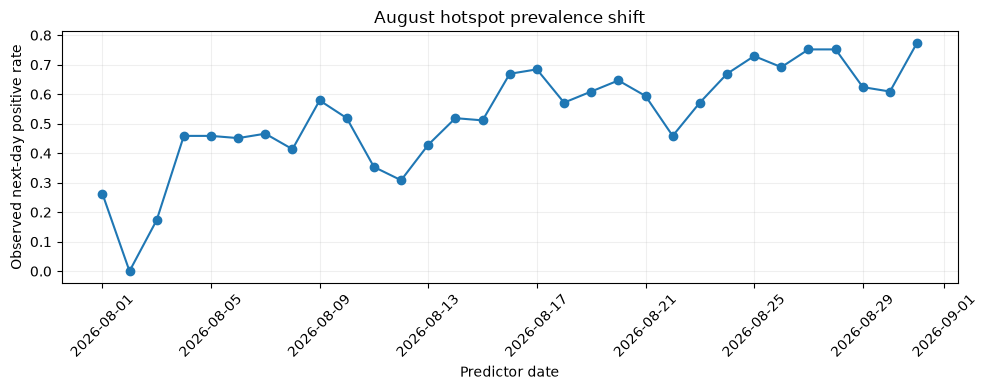

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_anomaly_decomposition\t2\figures\03_august_daily_positive_rate.png


In [21]:
# 19. Daily shift audit

daily_shift = (
    aug_scored
    .groupby("date")
    .agg(
        positive_rate=(TARGET, "mean"),
        positives=(TARGET, "sum"),
        mean_env_expected_lr=("env_expected_lr", "mean"),
        mean_env_expected_hgb=("env_expected_hgb", "mean"),
        mean_fire_expected_lr=("fire_expected_lr", "mean"),
    )
    .reset_index()
)

display(daily_shift.head())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    daily_shift["date"],
    daily_shift["positive_rate"],
    marker="o",
)
ax.set_ylabel("Observed next-day positive rate")
ax.set_xlabel("Predictor date")
ax.set_title("August hotspot prevalence shift")
ax.grid(alpha=0.2)

plt.xticks(rotation=45)
plt.tight_layout()

path = FIGURES_DIR / "03_august_daily_positive_rate.png"
plt.savefig(path, dpi=190, bbox_inches="tight")
plt.show()

print("Saved:", path)

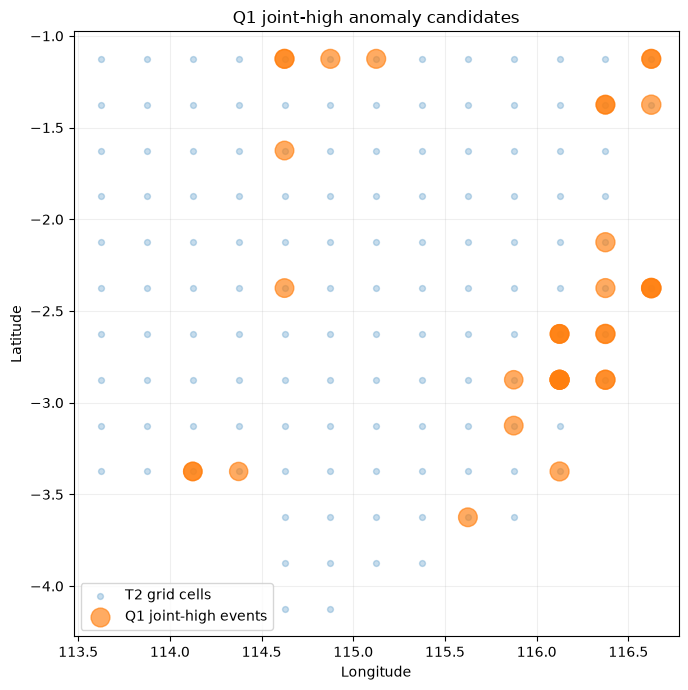

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_anomaly_decomposition\t2\figures\04_joint_high_candidate_map.png


In [22]:
# 20. Spatial audit of Q1 candidates

fig, ax = plt.subplots(figsize=(8, 7))

nodes = (
    aug_scored[
        ["cell_id", "grid_lon", "grid_lat"]
    ]
    .drop_duplicates()
)

ax.scatter(
    nodes["grid_lon"],
    nodes["grid_lat"],
    s=18,
    alpha=0.25,
    label="T2 grid cells",
)

if len(joint_candidates) > 0:
    sizes = (
        30
        + 170
        * joint_candidates["joint_rank_score"].to_numpy()
    )

    ax.scatter(
        joint_candidates["grid_lon"],
        joint_candidates["grid_lat"],
        s=sizes,
        alpha=0.65,
        label="Q1 joint-high events",
    )

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Q1 joint-high anomaly candidates")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

path = FIGURES_DIR / "04_joint_high_candidate_map.png"
plt.savefig(path, dpi=190, bbox_inches="tight")
plt.show()

print("Saved:", path)

In [23]:
# 21. Cell concentration / possible spatial artifact audit

cell_audit = (
    joint_candidates
    .groupby(["cell_id", "grid_lat", "grid_lon"])
    .agg(
        joint_events=("event_date", "size"),
        emerging_events=("is_emerging3", "sum"),
        mean_joint_rank=("joint_rank_score", "mean"),
        mean_env_rank=("env_anomaly_day_rank_lr", "mean"),
        mean_history_rank=("history_anomaly_day_rank", "mean"),
    )
    .reset_index()
    .sort_values(
        ["joint_events", "mean_joint_rank"],
        ascending=False,
    )
)

display(cell_audit.head(25))

if len(joint_candidates) > 0:
    top_cell_share = (
        cell_audit["joint_events"].head(5).sum()
        / len(joint_candidates)
    )
else:
    top_cell_share = np.nan

print("Share of Q1 events occurring in top 5 cells:", round(top_cell_share, 4))

,cell_id,grid_lat,grid_lon,joint_events,emerging_events,mean_joint_rank,mean_env_rank,mean_history_rank
13,regional025_6_32,-2.875,116.125,5,3,0.887970,0.933835,0.842105
19,regional025_8_34,-2.375,116.625,3,3,0.936717,0.994987,0.878446
15,regional025_7_32,-2.625,116.125,3,3,0.862782,0.849624,0.875940
14,regional025_6_33,-2.875,116.375,2,2,0.919173,0.954887,0.883459
16,regional025_7_33,-2.625,116.375,2,2,0.907895,0.954887,0.860902
3,regional025_13_26,-1.125,114.625,2,1,0.897556,0.887218,0.907895
6,regional025_13_34,-1.125,116.625,2,1,0.892857,0.913534,0.872180
1,regional025_12_33,-1.375,116.375,2,2,0.873120,0.857143,0.889098
8,regional025_4_24,-3.375,114.125,2,1,0.857143,0.838346,0.875940
2,regional025_12_34,-1.375,116.625,1,1,0.939850,0.992481,0.887218


Share of Q1 events occurring in top 5 cells: 0.4286


In [24]:
# 22. Static land/water audit for Q1 candidates

if STATIC_AUDIT_FEATURES:
    static_compare_rows = []

    for feature in STATIC_AUDIT_FEATURES:
        static_compare_rows.append({
            "Feature": feature,
            "All positive mean": float(pos[feature].mean()),
            "Q1 mean": (
                float(joint_candidates[feature].mean())
                if len(joint_candidates)
                else np.nan
            ),
            "All positive median": float(pos[feature].median()),
            "Q1 median": (
                float(joint_candidates[feature].median())
                if len(joint_candidates)
                else np.nan
            ),
        })

    static_audit = pd.DataFrame(static_compare_rows)
    display(static_audit)
else:
    static_audit = pd.DataFrame()
    print("No static land/water columns available for audit.")

,Feature,All positive mean,Q1 mean,All positive median,Q1 median
0,land_fraction,0.941617,0.761313,1.000000,0.818806
1,jrc_mean_water_occurrence,6.512031,20.996354,0.668355,14.682302
2,jrc_water_any_fraction,0.090336,0.227301,0.022394,0.157834
3,jrc_water50_fraction,0.064221,0.212914,0.003826,0.149838
4,jrc_water90_fraction,0.058809,0.206310,0.000135,0.143560


# PART D — Decision rule before GeoMAE

Notebook 23B is a **decision gate**.

Proceed toward masked self-supervised representation learning only if:

1. same-day environmental anomaly is not purely random / unstable;
2. LR and nonlinear HGB anomaly rankings have reasonable agreement;
3. Q1 candidates are not dominated by one obvious bad grid cell;
4. Q1 candidates are not explained by water/coastal artifacts;
5. there is a meaningful distinction between:
   - Q1 joint-high anomaly,
   - Q2 history-novel but environmentally plausible.

If these conditions fail, refine environmental/context data first.

If they hold, the next model should learn expected spatiotemporal structure without collapsing history novelty and environmental surprise into one score.

In [25]:
# 23. Save outputs

ALL_SCORED_PATH = EXPORT_DIR / "august_all_rows_anomaly_decomposition.csv"
POSITIVE_PATH = EXPORT_DIR / "august_positive_anomaly_decomposition.csv"
JOINT_PATH = EXPORT_DIR / "joint_high_anomaly_candidates.csv"
METRICS_PATH = EXPORT_DIR / "environmental_model_metrics.csv"
SUMMARY_PATH = EXPORT_DIR / "same_day_anomaly_group_summary.csv"
BOOTSTRAP_PATH = EXPORT_DIR / "bootstrap_group_differences.csv"
SENSITIVITY_PATH = EXPORT_DIR / "threshold_sensitivity.csv"
ROBUSTNESS_PATH = EXPORT_DIR / "environmental_model_robustness.csv"
DAILY_PATH = EXPORT_DIR / "august_daily_shift_audit.csv"
CELL_PATH = EXPORT_DIR / "joint_candidate_cell_audit.csv"
STATIC_PATH = EXPORT_DIR / "joint_candidate_static_audit.csv"
METADATA_PATH = EXPORT_DIR / "nb23b_methodology_metadata.json"

aug_scored.to_csv(ALL_SCORED_PATH, index=False)
pos.to_csv(POSITIVE_PATH, index=False)
joint_candidates.to_csv(JOINT_PATH, index=False)
model_metrics.to_csv(METRICS_PATH, index=False)
same_day_summary.to_csv(SUMMARY_PATH, index=False)
bootstrap_results.to_csv(BOOTSTRAP_PATH, index=False)
threshold_sensitivity.to_csv(SENSITIVITY_PATH, index=False)
robustness.to_csv(ROBUSTNESS_PATH, index=False)
daily_shift.to_csv(DAILY_PATH, index=False)
cell_audit.to_csv(CELL_PATH, index=False)

if len(static_audit):
    static_audit.to_csv(STATIC_PATH, index=False)

metadata = {
    "notebook": "23B_environmental_anomaly_decomposition",
    "train_period": {
        "start": str(TRAIN_START.date()),
        "end": str(TRAIN_END.date()),
    },
    "development_period": {
        "start": str(VAL_START.date()),
        "end": str(VAL_END.date()),
    },
    "september_used": False,
    "target": TARGET,
    "primary_history_model": "Logistic Regression on FIRE13",
    "primary_environment_model": "Logistic Regression on ENV10",
    "environment_sensitivity_model": "HistGradientBoosting on ENV10",
    "primary_anomaly_definition": (
        "within-predictor-day percentile rank across all T2 cells; "
        "higher means lower expectedness"
    ),
    "primary_screening_threshold": PRIMARY_THRESHOLD,
    "quadrant_of_interest": (
        "Q1 Joint-high anomaly candidate = high history anomaly "
        "and high environmental anomaly"
    ),
    "important_limit": (
        "Q1 is not an anthropogenic, intentional-burning, illegal-burning, "
        "plantation-clearing, or natural-ignition label."
    ),
}

METADATA_PATH.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Saved outputs to:", EXPORT_DIR)

Saved outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\environmental_anomaly_decomposition\t2\exports


In [26]:
# 24. Automatic interpretation summary

print("=== NB23B automatic interpretation ===")
print()

display(same_day_summary)
print()

lr_hgb_corr = float(
    robustness.loc[
        robustness["Metric"].eq("Rank correlation LR vs HGB"),
        "Value",
    ].iloc[0]
)

lr_hgb_jaccard = float(
    robustness.loc[
        robustness["Metric"].eq("Top-20% environmental anomaly Jaccard"),
        "Value",
    ].iloc[0]
)

print(f"Environmental LR-vs-HGB rank agreement : {lr_hgb_corr:.3f}")
print(f"Top-20% environmental Jaccard          : {lr_hgb_jaccard:.3f}")
print(f"Q1 joint-high candidates               : {len(joint_candidates)}")

if len(joint_candidates):
    q1_emerging_share = float(joint_candidates["is_emerging3"].mean())
    print(f"Emerging-3 share among Q1              : {q1_emerging_share:.3f}")

print()

if lr_hgb_corr >= 0.70:
    print(
        "Environmental anomaly ranking is reasonably robust to model form."
    )
else:
    print(
        "Environmental anomaly ranking is model-sensitive; "
        "refine the environmental expectedness model before freezing anomaly labels."
    )

print()

print(
    "Do NOT interpret Q1 as anthropogenic fire. "
    "The next causal/contextual step requires external evidence."
)

=== NB23B automatic interpretation ===



,research_group,events,history_mean,history_median,env_lr_mean,env_lr_median,env_hgb_mean,env_hgb_median
0,Emerging-3,224,0.755119,0.796992,0.544945,0.567669,0.535731,0.552632
1,Persistent,1945,0.310248,0.278195,0.481539,0.496241,0.487210,0.484962



Environmental LR-vs-HGB rank agreement : 0.505
Top-20% environmental Jaccard          : 0.231
Q1 joint-high candidates               : 35
Emerging-3 share among Q1              : 0.829

Environmental anomaly ranking is model-sensitive; refine the environmental expectedness model before freezing anomaly labels.

Do NOT interpret Q1 as anthropogenic fire. The next causal/contextual step requires external evidence.


# What to send for review

After **Run All**, send the executed NB23B notebook, or at minimum these outputs:

1. `model_metrics`
2. `same_day_summary`
3. `bootstrap_results`
4. `quadrant_counts`
5. `quadrant_share`
6. `robustness`
7. `threshold_sensitivity`
8. top 30 rows of `joint_candidates`
9. `cell_audit`
10. `static_audit`
11. Figures 01–04

From those results we decide between:

### Path A
Environmental anomaly is sufficiently stable  
→ proceed to **NB24 masked spatiotemporal pretraining / GeoMAE-inspired representation learning**.

### Path B
Environmental anomaly remains weak or model-sensitive  
→ add/refine environmental/context features first, especially lightning and land-use context, before GeoMAE.